#  GWAS tutorial

Prepared By: Udayaraja GK

Supervised By: Haja N Kadarmideen

# iMAP-Dairy (DKC) subset

**Data:** 588 genotyped cows (DKC, Aarhus University), BovineSNP50-type array,
12,747 SNPs. **BTA1 and BTA14 are at full density** (2,448 and 1,299 SNPs); the other 27 autosomes are
randomly thinned (~9k SNPs) so that population structure, the kinship matrix (GRM) and
leave-one-chromosome-out (LOCO) models can be built inside the notebook.

**Traits** (from `ml_targets.csv`):

| trait | type | definition |
|---|---|---|
| `my305` | quantitative | 305-d milk yield (kg), one record per cow |
| `rfi` | quantitative | residual feed intake (as-fed, i.e. residual *fresh* intake) |
| `mastitis` | binary (≈10 % cases) | clinical mastitis case/control from treatment records |

**Steps:** setup → phenotypes → genotype QC → LD decay & pruning → population structure (PCA, GRM) →
SNP heritability (REML) → association (naive LM / LM + PCs / LMM-LOCO) → significance thresholds
(Bonferroni, M_eff) → Manhattan, QQ, Miami → clumping & lead SNPs → regional association plot →
conditional analysis → genotype–phenotype and cross-trait effect plots → summary.

**Tools:** PLINK 2.0 (QC, LM/logistic GLM, PCA, clumping) and GCTA 1.94 (GRM, REML, MLMA-LOCO).

## Setup

Works on **Google Colab** (Linux x86-64) or any Linux/WSL machine. If `plink2`/`gcta64` are not on
`PATH`, the cell installs them from bioconda with `micromamba` (~1–2 min, no root needed).
On macOS use `environment.yml` (`conda env create -f environment.yml`); GCTA on Apple silicon may
need Rosetta.

In [ ]:
import os, sys, shutil, subprocess, glob, zipfile, re
IN_COLAB = 'google.colab' in sys.modules
ENV = os.path.abspath('gwas_env')
if os.path.isdir(ENV + '/bin'):
    os.environ['PATH'] = ENV + '/bin:' + os.environ['PATH']

def have_tools():
    return shutil.which('plink2') is not None and shutil.which('gcta64') is not None

if not have_tools():
    print('Installing plink2 + gcta via micromamba (bioconda) ...')
    subprocess.run('curl -sL -o micromamba https://github.com/mamba-org/micromamba-releases/releases/latest/download/micromamba-linux-64 && chmod +x micromamba',
                   shell=True, check=True)
    subprocess.run(f'./micromamba create -y -q -p {ENV} -c conda-forge -c bioconda plink2 gcta',
                   shell=True, check=True, env={**os.environ, 'MAMBA_ROOT_PREFIX': os.path.abspath('mamba_root')})
    os.environ['PATH'] = ENV + '/bin:' + os.environ['PATH']

print(subprocess.run('plink2 --version', shell=True, capture_output=True, text=True).stdout.strip())
print([l for l in subprocess.run('gcta64', shell=True, capture_output=True, text=True).stdout.splitlines() if 'version' in l][0].strip(' *'))

Installing plink2 + gcta via micromamba (bioconda) ...
PLINK v2.0.0-a.7.8 64-bit (19 Sep 2026)
version v1.94.1 Linux


### Data

Data lives in the MSB GitHub repo, at `tutorials/03_GWAS_iMAP/data/` (`imap_genomewide_panel.{bed,bim,fam}` and `pheno.txt`).
The next cell clones the repo automatically — nothing to upload, no Google Drive mount needed.

In [ ]:
REPO_URL = 'https://github.com/udayaraja/MSB.git'
REPO_DIR = os.path.abspath('MSB')

if not os.path.isdir(os.path.join(REPO_DIR, '.git')):
    print('Cloning MSB repo (shallow)...')
    subprocess.run(f'git clone --depth 1 {REPO_URL} {REPO_DIR}', shell=True, check=True)
else:
    print('MSB repo already present — pulling latest...')
    subprocess.run(f'git -C {REPO_DIR} pull --ff-only', shell=True, check=True)

DATA_DIR = f'{REPO_DIR}/tutorials/03_GWAS_iMAP/data'           # data ships inside the repo
PREFIX = f'{DATA_DIR}/imap_genomewide_panel'
if not os.path.exists(PREFIX + '.bed'):
    raise FileNotFoundError(f'{PREFIX}.bed not found — check repo contents at {REPO_DIR}')

os.chdir(f'{REPO_DIR}/tutorials/03_GWAS_iMAP')
os.makedirs('out', exist_ok=True); os.makedirs('figures', exist_ok=True)
print('DATA_DIR =', DATA_DIR); print(sorted(os.listdir(DATA_DIR)))

### Helpers (shell wrapper, file readers, plot style)

In [ ]:
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list

PL = 'plink2 --cow --nonfounders --threads 2 --input-missing-phenotype -999999'  # rfi can legitimately be ≈ -9 (PLINK's default missing code); only NA = missing   # all cows have recorded parents -> 'nonfounders' in PLINK terms
GC = 'gcta64 --autosome-num 29 --thread-num 2'

def run(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:]); raise RuntimeError(cmd)
    return r.stdout

def read_tab(path):
    d = pd.read_csv(path, sep=r'\s+')
    d.columns = [c.lstrip('#') for c in d.columns]
    if 'IID' in d and 'FID' not in d: d.insert(0, 'FID', d['IID'])
    return d

def read_bim(prefix):
    return pd.read_csv(prefix + '.bim', sep=r'\s+', header=None, names=['CHR','SNP','CM','BP','A1','A2'])

def load_dosage(bfile, snps=None, tag='tmp'):
    # additive dosage (count of ALT = bim A1 allele) for a SNP set -> DataFrame (animals x SNPs)
    ext = ''
    if snps is not None:
        pd.Series(list(snps)).to_csv(f'out/{tag}.snps', index=False, header=False); ext = f'--extract out/{tag}.snps'
    run(f'{PL} --bfile {bfile} {ext} --export A --out out/{tag}')
    raw = pd.read_csv(f'out/{tag}.raw', sep=r'\s+')
    X = raw.iloc[:, 6:]; X.index = raw['IID'].values
    COUNTED.update({re.sub(r'_[^_]+$', '', c): c.rsplit('_', 1)[1] for c in X.columns})  # allele actually counted
    X.columns = [re.sub(r'_[^_]+$', '', c) for c in X.columns]
    return X
COUNTED = {}   # NB: GCTA/PLINK GWAS betas are per copy of A1 (bim col 5); check which allele the dosage counts

def read_grm(prefix):
    ids = pd.read_csv(prefix + '.grm.id', sep=r'\s+', header=None)
    n = len(ids); v = np.fromfile(prefix + '.grm.bin', dtype=np.float32)
    G = np.zeros((n, n), dtype=np.float32); il = np.tril_indices(n)
    G[il] = v; G = G + G.T - np.diag(np.diag(G))
    return G, ids[1].values

def lam_gc(p):
    p = np.asarray(p, float); p = p[np.isfinite(p) & (p > 0)]
    return np.median(stats.chi2.isf(p, 1)) / stats.chi2.ppf(0.5, 1)

# --- plot style: one validated categorical order; Manhattan = two shades of one hue ---
C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100',
         violet='#6250d6', red='#e34948', light='#86b6ef', ink='#0b0b0b', ink2='#52514e', grid='#e6e5e0')
MODEL_COL = {'naive LM': C['orange'], 'LM + 5 PCs': C['yellow'], 'LMM-LOCO': C['blue']}
mpl.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': C['ink2'],
    'axes.labelcolor': C['ink'], 'xtick.color': C['ink2'], 'ytick.color': C['ink2'],
    'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False,
    'lines.linewidth': 2, 'figure.dpi': 110})
def save(fig, name):
    fig.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

## 1. Phenotypes

One record per cow (no repeated measures in this table). Check distributions and outliers before
any association analysis — a heavy tail in a quantitative trait inflates test statistics.

,count,mean,std,min,25%,50%,75%,max
my305,588.0,8576.57,1301.67,4837.00,7716.25,8529.00,9460.25,12684.00
rfi,584.0,0.68,4.39,-21.36,-1.34,0.97,3.38,14.31
mastitis,588.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00


mastitis prevalence = 0.102


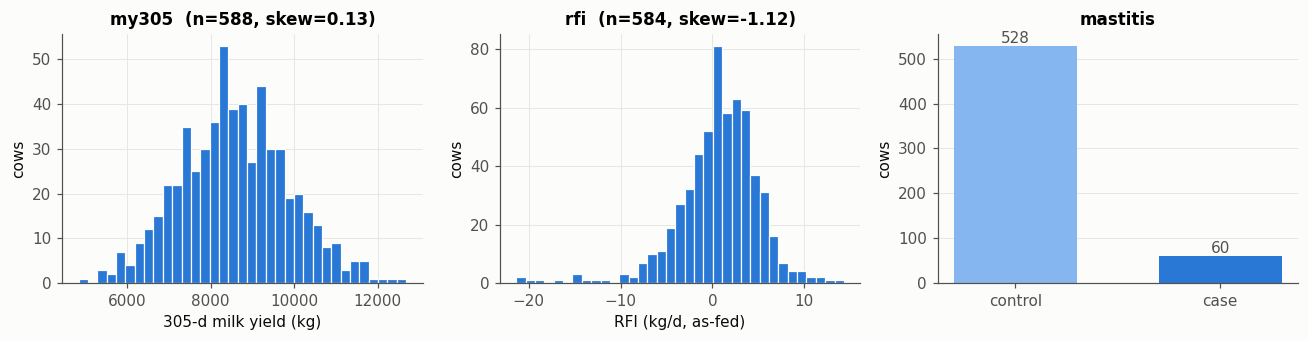

In [ ]:
pheno = pd.read_csv(f'{DATA_DIR}/pheno.txt', sep='\t')
TRAITS = ['my305', 'rfi', 'mastitis']
display(pheno[TRAITS].describe().T.round(2))
prev = pheno['mastitis'].mean(); print(f'mastitis prevalence = {prev:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, t, lab in [(ax[0], 'my305', '305-d milk yield (kg)'), (ax[1], 'rfi', 'RFI (kg/d, as-fed)')]:
    x = pheno[t].dropna(); a.hist(x, bins=35, color=C['blue'], edgecolor='#fcfcfb', linewidth=0.8)
    a.set_xlabel(lab); a.set_ylabel('cows'); a.set_title(f'{t}  (n={len(x)}, skew={stats.skew(x):.2f})')
cnt = pheno['mastitis'].value_counts().sort_index()
ax[2].bar(['control', 'case'], cnt.values, color=[C['light'], C['blue']], width=0.6)
for i, v in enumerate(cnt.values): ax[2].text(i, v, f'{v}', ha='center', va='bottom', color=C['ink2'])
ax[2].set_title('mastitis'); ax[2].set_ylabel('cows'); ax[2].grid(axis='x')
fig.tight_layout(); save(fig, '01_phenotypes')

## 2. Genotype QC

The panel was already filtered upstream (`--geno 0.05 --maf 0.01`, low-density-chip cows removed).
Here we recompute every standard QC metric and re-apply filters so the steps are explicit:

| metric | filter used | rationale |
|---|---|---|
| sample call rate | `--mind 0.10` | failed / low-quality DNA |
| SNP call rate | `--geno 0.05` | poorly clustering assays |
| MAF | `--maf 0.01` | too few minor-allele carriers for stable tests at n≈600 |
| HWE exact test | `--hwe 1e-6` | lenient: selection and relatedness in a single herd legitimately distort HWE; in a mixed-breed cohort test **within breed** |
| heterozygosity F | inspect only | outliers suggest contamination (F≪0) or inbreeding / sample mix-up (F≫0) |

SNPs: 12747 -> 12730   cows: 588 -> 588
HWE p<1e-6: 17 SNPs;  |F| > 3 SD: 2 cows (flagged, kept)


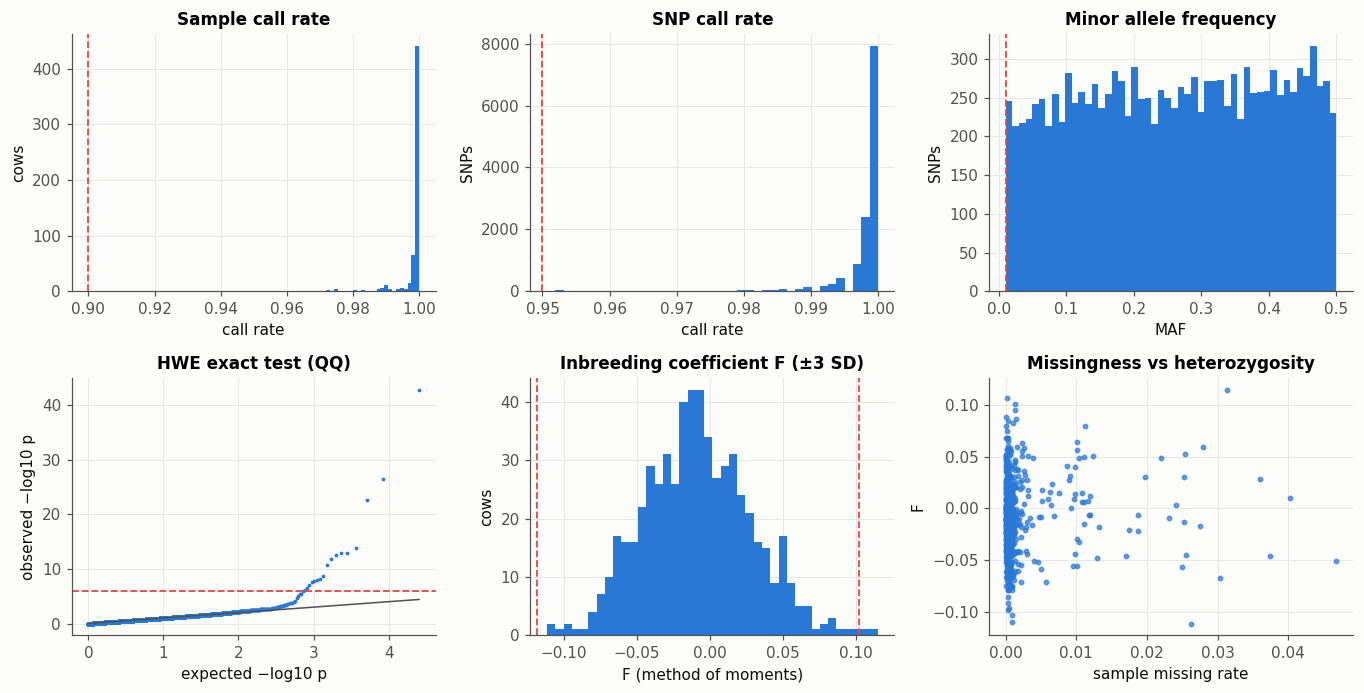

In [ ]:
run(f'{PL} --bfile {PREFIX} --missing --freq --hardy --het --out out/qc_raw')
smiss, vmiss = read_tab('out/qc_raw.smiss'), read_tab('out/qc_raw.vmiss')
afreq, hardy, het = read_tab('out/qc_raw.afreq'), read_tab('out/qc_raw.hardy'), read_tab('out/qc_raw.het')
maf = np.minimum(afreq.ALT_FREQS, 1 - afreq.ALT_FREQS)

fig, ax = plt.subplots(2, 3, figsize=(12.5, 6.4))
ax[0,0].hist(1 - smiss.F_MISS, bins=40, color=C['blue']); ax[0,0].axvline(0.90, color=C['red'], lw=1.2, ls='--')
ax[0,0].set(title='Sample call rate', xlabel='call rate', ylabel='cows')
ax[0,1].hist(1 - vmiss.F_MISS, bins=40, color=C['blue']); ax[0,1].axvline(0.95, color=C['red'], lw=1.2, ls='--')
ax[0,1].set(title='SNP call rate', xlabel='call rate', ylabel='SNPs')
ax[0,2].hist(maf, bins=50, color=C['blue']); ax[0,2].axvline(0.01, color=C['red'], lw=1.2, ls='--')
ax[0,2].set(title='Minor allele frequency', xlabel='MAF', ylabel='SNPs')
obs = np.sort(-np.log10(hardy.P.values)); n_h = len(obs)
e = np.sort(-np.log10((np.arange(1, n_h + 1) - 0.5) / n_h))
ax[1,0].scatter(e, obs, s=6, color=C['blue'], linewidth=0)
ax[1,0].plot([0, e.max()], [0, e.max()], color=C['ink2'], lw=1); ax[1,0].axhline(6, color=C['red'], lw=1.2, ls='--')
ax[1,0].set(title='HWE exact test (QQ)', xlabel='expected −log10 p', ylabel='observed −log10 p')
ax[1,1].hist(het.F, bins=40, color=C['blue']); m, s = het.F.mean(), het.F.std()
for k in (-3, 3): ax[1,1].axvline(m + k*s, color=C['red'], lw=1.2, ls='--')
ax[1,1].set(title='Inbreeding coefficient F (±3 SD)', xlabel='F (method of moments)', ylabel='cows')
ax[1,2].scatter(smiss.F_MISS, het.F, s=8, color=C['blue'], alpha=0.7)
ax[1,2].set(title='Missingness vs heterozygosity', xlabel='sample missing rate', ylabel='F')
fig.tight_layout(); save(fig, '02_qc_panels')

run(f'{PL} --bfile {PREFIX} --mind 0.10 --geno 0.05 --maf 0.01 --hwe 1e-6 --make-founders --make-bed --out out/qc')   # parents not genotyped -> treat as founders (needed for LD pruning)
QC = 'out/qc'
bim = read_bim(QC); n_in, n_out = len(read_bim(PREFIX)), len(bim)
print(f'SNPs: {n_in} -> {n_out}   cows: {len(smiss)} -> {sum(1 for _ in open(QC + ".fam"))}')
print(f'HWE p<1e-6: {(hardy.P < 1e-6).sum()} SNPs;  |F| > 3 SD: {((het.F - m).abs() > 3*s).sum()} cows (flagged, kept)')

## 3. Linkage disequilibrium: decay and pruning

LD extent sets the mapping resolution and the window for clumping. Holstein LD decays slowly
(r² ≈ 0.2 at a few hundred kb) because of small effective population size. Decay is computed on the
**full-density chromosomes** (BTA1, BTA14) only — thinned chromosomes would bias it.

LD-pruned SNPs for PCA: 4299


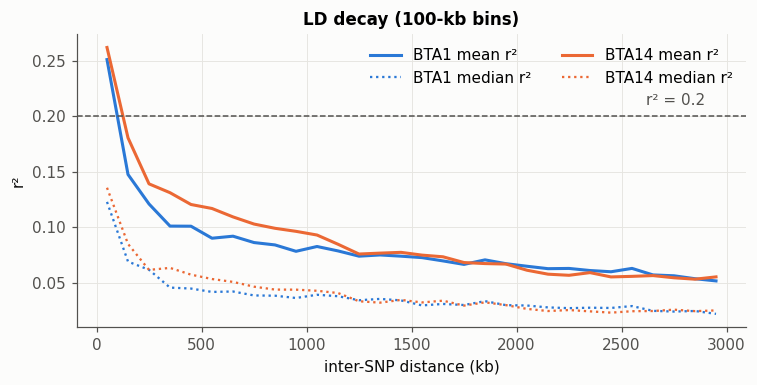

In [ ]:
def ld_decay(chrom, maxd=3e6, binw=100e3):
    b = bim[bim.CHR == chrom].sort_values('BP')
    X = load_dosage(QC, b.SNP, tag=f'ld{chrom}')[b.SNP.values]
    X = X.fillna(X.mean()); R2 = np.corrcoef(X.values.T) ** 2
    pos = b.BP.values; i, j = np.triu_indices(len(pos), 1)
    d = np.abs(pos[j] - pos[i]); keep = d <= maxd
    df = pd.DataFrame({'bin': (d[keep] // binw) * binw + binw/2, 'r2': R2[i[keep], j[keep]]})
    return df.groupby('bin').r2.agg(['mean', 'median']).reset_index()

fig, ax = plt.subplots(figsize=(7, 3.6))
for chrom, col in [(1, C['blue']), (14, C['orange'])]:
    dd = ld_decay(chrom); ax.plot(dd['bin']/1e3, dd['mean'], color=col, label=f'BTA{chrom} mean r²')
    ax.plot(dd['bin']/1e3, dd['median'], color=col, ls=':', lw=1.5, label=f'BTA{chrom} median r²')
ax.axhline(0.2, color=C['ink2'], lw=1, ls='--'); ax.text(2900, 0.21, 'r² = 0.2', ha='right', color=C['ink2'])
ax.set(xlabel='inter-SNP distance (kb)', ylabel='r²', title='LD decay (100-kb bins)'); ax.legend(ncol=2)
fig.tight_layout(); save(fig, '03_ld_decay')

run(f'{PL} --bfile {QC} --indep-pairwise 50 5 0.2 --out out/prune')
print('LD-pruned SNPs for PCA:', sum(1 for _ in open('out/prune.prune.in')))

## 4. Population structure and relatedness

* **PCA** on LD-pruned SNPs → top PCs as fixed covariates (controls broad stratification, e.g. breed or sire-line).
* **GRM** (GCTA, VanRaden-type standardised) → random polygenic effect in the LMM (controls cryptic relatedness, which PCs cannot).

A single-herd dairy cohort is dominated by **relatedness** (paternal half-sib families via AI sires),
not discrete subpopulations — look at the flat scree plot and the off-diagonal GRM tail.

pairs with G_ij > 0.177 (≥ ~2nd degree): 2354;  > 0.354 (~1st degree): 300


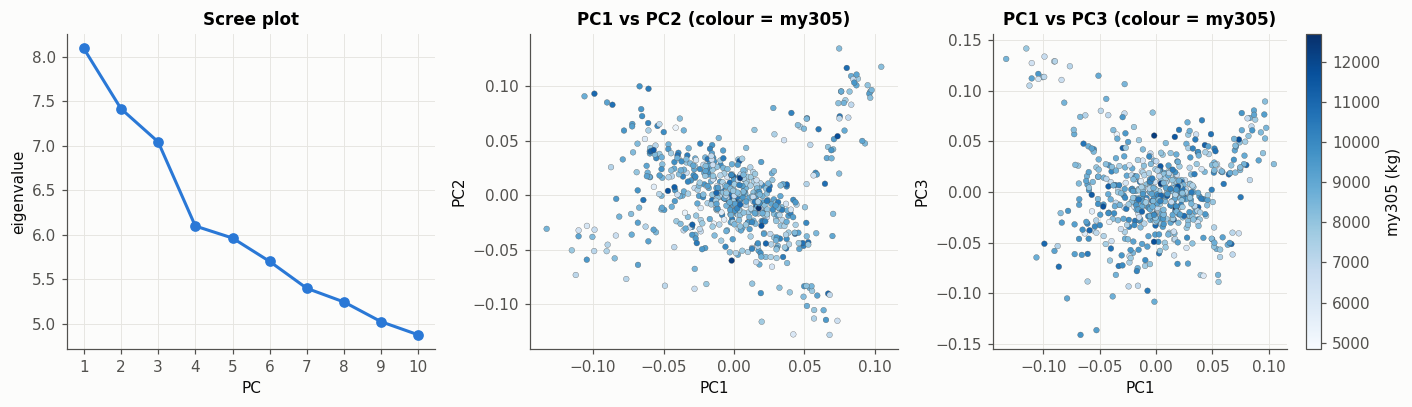

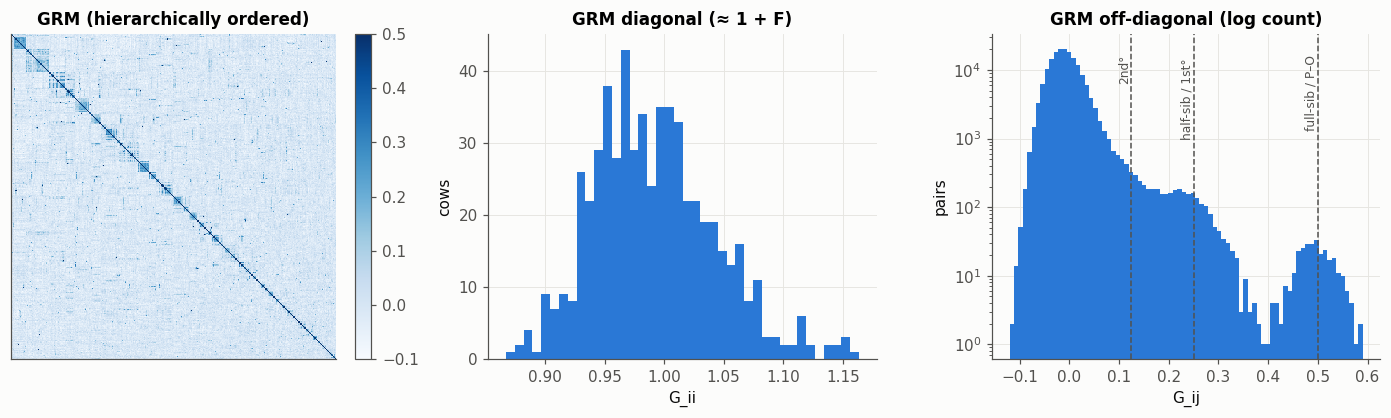

In [ ]:
run(f'{PL} --bfile {QC} --extract out/prune.prune.in --pca 10 --out out/pca')
pcs = read_tab('out/pca.eigenvec'); evals = np.loadtxt('out/pca.eigenval')
pcs[['FID','IID','PC1','PC2','PC3','PC4','PC5']].to_csv('out/pcs5.qcovar', sep=' ', header=False, index=False)
pp = pcs.merge(pheno, on=['FID','IID'])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(range(1, 11), evals, marker='o', ms=6, color=C['blue']); ax[0].set(title='Scree plot', xlabel='PC', ylabel='eigenvalue'); ax[0].set_xticks(range(1, 11))
for a, (x, y) in zip(ax[1:], [('PC1','PC2'), ('PC1','PC3')]):
    sc = a.scatter(pp[x], pp[y], c=pp['my305'], cmap='Blues', s=14, edgecolor=C['ink2'], linewidth=0.2)
    a.set(xlabel=x, ylabel=y, title=f'{x} vs {y} (colour = my305)')
fig.colorbar(sc, ax=ax[2], label='my305 (kg)'); fig.tight_layout(); save(fig, '04_pca')

run(f'{GC} --bfile {QC} --make-grm --out out/grm')
G, gid = read_grm('out/grm')
off = G[np.triu_indices_from(G, 1)]; order = leaves_list(linkage(G, 'average'))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
im = ax[0].imshow(G[np.ix_(order, order)], cmap='Blues', vmin=-0.1, vmax=0.5, interpolation='nearest')
ax[0].set(title='GRM (hierarchically ordered)', xticks=[], yticks=[]); ax[0].grid(False); fig.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].hist(np.diag(G), bins=40, color=C['blue']); ax[1].set(title='GRM diagonal (≈ 1 + F)', xlabel='G_ii', ylabel='cows')
ax[2].hist(off, bins=80, color=C['blue'], log=True)
for v, lab in [(0.125, '2nd°'), (0.25, 'half-sib / 1st° '), (0.5, 'full-sib / P–O')]:
    ax[2].axvline(v, color=C['ink2'], ls='--', lw=1); ax[2].text(v, ax[2].get_ylim()[1]*0.5, lab, rotation=90, va='top', ha='right', color=C['ink2'], fontsize=8)
ax[2].set(title='GRM off-diagonal (log count)', xlabel='G_ij', ylabel='pairs')
fig.tight_layout(); save(fig, '05_grm')
print(f'pairs with G_ij > 0.177 (≥ ~2nd degree): {(off > 0.177).sum()};  > 0.354 (~1st degree): {(off > 0.354).sum()}')

## 5. SNP heritability (GREML)

`h²_SNP = V(G)/V(P)` with 5 PCs as covariates. For mastitis GCTA also reports the
**liability-scale** estimate (Lee et al. 2011 transform, population prevalence = observed 0.10 —
an assumption; replace with the herd/national incidence if known). With n≈600 the SEs are large:
these are sanity checks, not publishable estimates.

,trait,scale,h2,se
0,my305,observed,0.419,0.077
1,rfi,observed,0.407,0.084
2,mastitis,liability,0.527,0.216


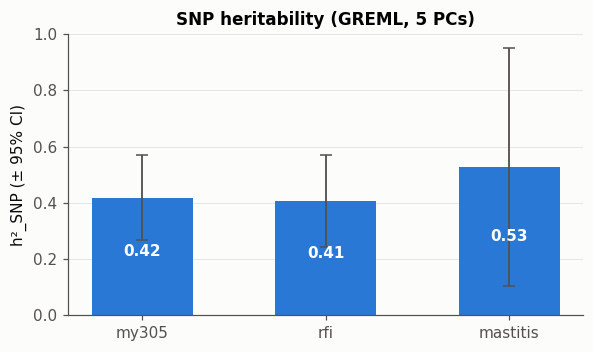

In [ ]:
def write_phen(t):
    pheno[['FID','IID',t]].to_csv(f'out/{t}.phen', sep=' ', header=False, index=False, na_rep='NA')
    return f'out/{t}.phen'

def read_hsq(path):
    d = pd.read_csv(path, sep='\t', nrows=12, on_bad_lines='skip'); d.columns = ['Source','Variance','SE'][:d.shape[1]]
    return d.set_index('Source')

h2 = []
for t in TRAITS:
    extra = f'--prevalence {prev:.3f}' if t == 'mastitis' else ''
    run(f'{GC} --reml --grm out/grm --pheno {write_phen(t)} --qcovar out/pcs5.qcovar {extra} --out out/reml_{t}')
    h = read_hsq(f'out/reml_{t}.hsq')
    key = 'V(G)/Vp_L' if t == 'mastitis' and 'V(G)/Vp_L' in h.index else 'V(G)/Vp'
    h2.append(dict(trait=t, scale='liability' if key.endswith('_L') else 'observed',
                   h2=float(h.loc[key,'Variance']), se=float(h.loc[key,'SE'])))
h2 = pd.DataFrame(h2); display(h2.round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.bar(h2.trait, h2.h2, yerr=1.96*h2.se, color=C['blue'], width=0.55, capsize=4, error_kw=dict(ecolor=C['ink2'], lw=1.2))
for i, r in h2.iterrows(): ax.text(i, r.h2/2, f'{r.h2:.2f}', ha='center', color='white', fontweight='bold')
ax.set(ylabel='h²_SNP (± 95% CI)', title='SNP heritability (GREML, 5 PCs)', ylim=(0, 1)); ax.grid(axis='x')
fig.tight_layout(); save(fig, '06_h2')

## 6. Association testing — three models

| model | tool | controls for | note |
|---|---|---|---|
| **naive LM** | `plink2 --glm` (no covariates) | nothing | shows what uncontrolled relatedness does |
| **LM + 5 PCs** | `plink2 --glm` + PCs | broad stratification | logistic (Firth fallback) for mastitis |
| **LMM-LOCO** | `gcta64 --mlma-loco` + PCs | stratification **and** relatedness | GRM omits the tested chromosome → no proximal contamination |

For **mastitis** the LMM is a *linear* mixed model on the 0/1 outcome (effects on the observed
risk scale). This is the standard fast approximation for case/control LMM GWAS at low prevalence;
exact logistic GLMMs (e.g. SAIGE / GMMAT) are more accurate for very rare cases but slower.

In [ ]:
def std_plink(prefix, trait, model):
    f = [x for x in glob.glob(f'{prefix}.{trait}.glm.*') if not x.endswith('.id')][0]
    d = read_tab(f); d = d[d.TEST == 'ADD'].copy()
    if 'BETA' in d: beta, se = d.BETA, d.SE
    else:           beta, se = np.log(d.OR), d['LOG(OR)_SE']
    return pd.DataFrame(dict(CHR=d.CHROM.astype(int), BP=d.POS, SNP=d.ID, A1=d.A1, FREQ=d.A1_FREQ,
                             BETA=beta.values, SE=se.values, P=d.P, trait=trait, model=model))

def std_gcta(path, trait, model):
    d = read_tab(path)
    return pd.DataFrame(dict(CHR=d.Chr, BP=d.bp, SNP=d.SNP, A1=d.A1, FREQ=d.Freq, BETA=d.b, SE=d.se,
                             P=d.p, trait=trait, model=model))

res = []
for t in TRAITS:
    binflag = '--1' if t == 'mastitis' else ''
    glm = 'firth-fallback' if t == 'mastitis' else ''
    run(f'{PL} --bfile {QC} --pheno {DATA_DIR}/pheno.txt --pheno-name {t} {binflag} --glm {glm} allow-no-covars --out out/naive')
    res.append(std_plink('out/naive', t, 'naive LM'))
    run(f'{PL} --bfile {QC} --pheno {DATA_DIR}/pheno.txt --pheno-name {t} {binflag} --covar out/pca.eigenvec --covar-name PC1-PC5 '
        f'--covar-variance-standardize --glm {glm} hide-covar --out out/pc5')
    res.append(std_plink('out/pc5', t, 'LM + 5 PCs'))
    run(f'{GC} --mlma-loco --bfile {QC} --pheno out/{t}.phen --qcovar out/pcs5.qcovar --out out/lmm_{t}')
    res.append(std_gcta(f'out/lmm_{t}.loco.mlma', t, 'LMM-LOCO'))
res = pd.concat(res, ignore_index=True).dropna(subset=['P'])
res.to_csv('out/gwas_all_results.tsv.gz', sep='\t', index=False)

lam = res.groupby(['trait','model']).P.apply(lam_gc).unstack()[list(MODEL_COL)]
display(lam.round(3).style.background_gradient(cmap='Oranges', vmin=1, vmax=1.6).format('{:.2f}').set_caption('genomic inflation λ_GC'))

model,naive LM,LM + 5 PCs,LMM-LOCO
trait,,,
mastitis,1.13,1.20,1.01
my305,1.59,1.54,1.14
rfi,1.88,1.22,1.07


## 7. Genome-wide significance thresholds

* **Bonferroni** on all tested SNPs (`0.05 / M`) — conservative because SNPs are correlated.
* **M_eff (simpleM, Gao et al. 2008)**: per chromosome, the number of principal components of the SNP
  correlation matrix explaining 99.5 % of variance; `0.05 / ΣM_eff` (significant) and `1 / ΣM_eff`
  (suggestive: ~1 false positive per scan).
* A **permutation** threshold (max-statistic over ~1,000 phenotype permutations) is the gold standard;
  omitted here to keep run time low.

In [ ]:
Xall = load_dosage(QC, tag='all'); Xall = Xall.fillna(Xall.mean())
meff = 0
for chrom, b in bim.groupby('CHR'):
    ev = np.clip(np.linalg.eigvalsh(np.corrcoef(Xall[b.SNP].values.T)), 0, None)[::-1]
    meff += int(np.searchsorted(np.cumsum(ev) / ev.sum(), 0.995) + 1)
M = len(bim)
THR = dict(bonf=0.05 / M, sig=0.05 / meff, sugg=1 / meff)
print(f'M = {M},  M_eff = {meff}')
print({k: f'{v:.2e} (−log10 = {-np.log10(v):.2f})' for k, v in THR.items()})

M = 12730,  M_eff = 6884
{'bonf': '3.93e-06 (−log10 = 5.41)', 'sig': '7.26e-06 (−log10 = 5.14)', 'sugg': '1.45e-04 (−log10 = 3.84)'}


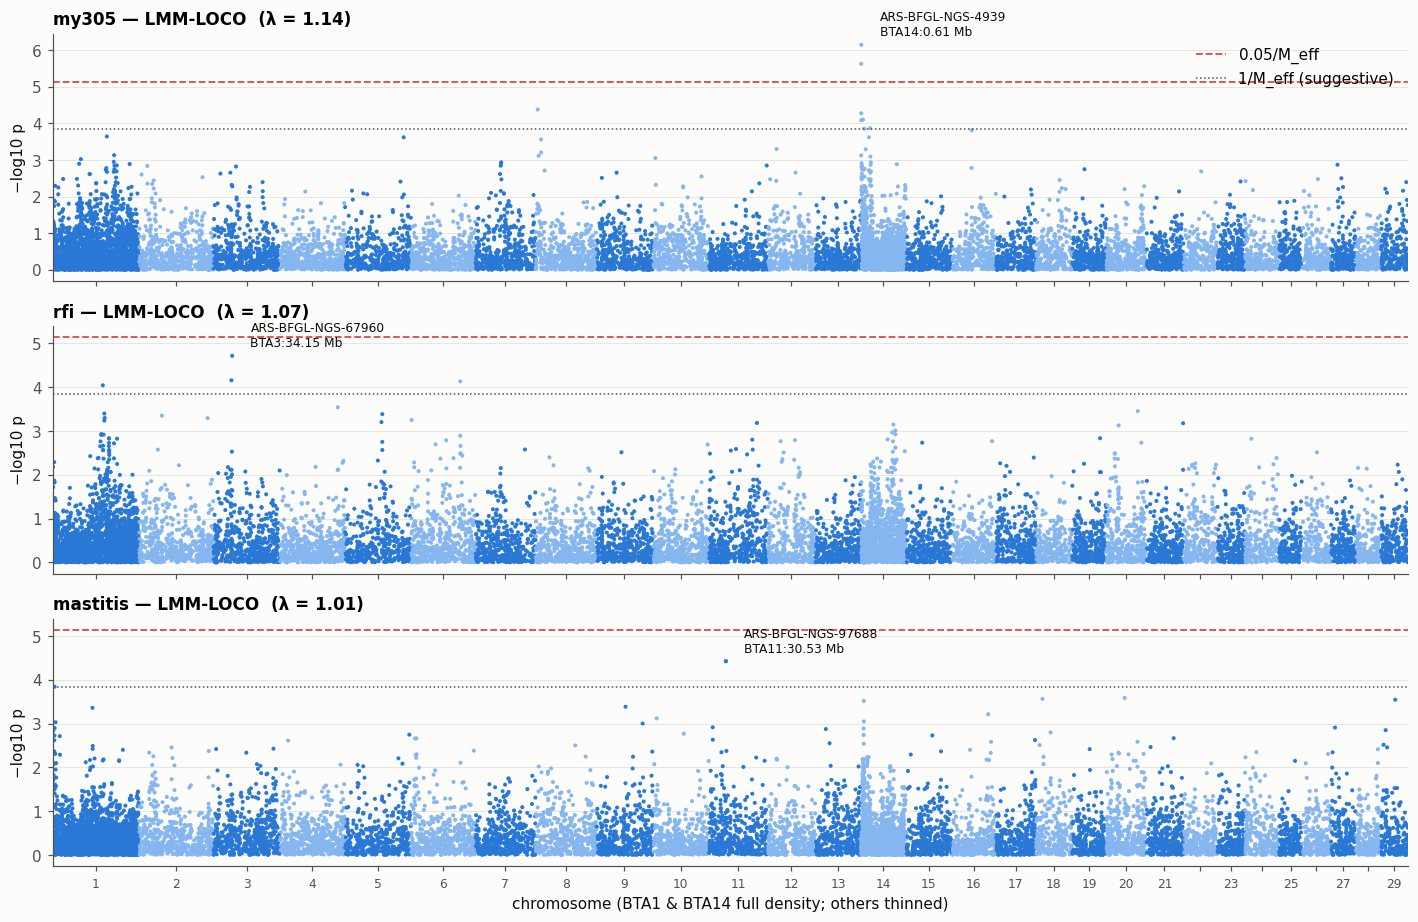

In [ ]:
chr_len = bim.groupby('CHR').BP.max(); offset = chr_len.cumsum() - chr_len
ticks = offset + chr_len / 2

def add_xpos(d): return d.assign(X=d.BP + d.CHR.map(offset).values)

def manhattan(ax, d, title, flip=False, annotate=True):
    d = add_xpos(d); y = -np.log10(d.P) * (-1 if flip else 1)
    cols = np.where(d.CHR % 2 == 1, C['blue'], C['light'])
    ax.scatter(d.X, y, c=cols, s=7, linewidth=0, rasterized=True)
    sgn = -1 if flip else 1
    ax.axhline(sgn * -np.log10(THR['sig']), color=C['red'], lw=1.2, ls='--')
    ax.axhline(sgn * -np.log10(THR['sugg']), color=C['ink2'], lw=1, ls=':')
    ax.set_xticks(ticks.values); ax.set_xticklabels([str(c) if c <= 20 or c % 2 == 1 else '' for c in ticks.index], fontsize=8)
    ax.set_xlim(0, (offset + chr_len).max()); ax.grid(axis='x'); ax.set_ylabel('−log10 p' if not flip else '−log10 p (↓)')
    ax.set_title(title, loc='left')
    if annotate:
        top = d.loc[d.P.idxmin()]
        if top.P < THR['sugg']:
            ax.annotate(f"{top.SNP}\nBTA{top.CHR}:{top.BP/1e6:.2f} Mb", (top.X, sgn * -np.log10(top.P)),
                        xytext=(12, -14 if flip else 6), textcoords='offset points', fontsize=8, color=C['ink'])
    if flip: ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{abs(v):g}'))

lmm = res[res.model == 'LMM-LOCO']
fig, ax = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)
for a, t in zip(ax, TRAITS):
    manhattan(a, lmm[lmm.trait == t], f'{t} — LMM-LOCO  (λ = {lam.loc[t, "LMM-LOCO"]:.2f})')
ax[-1].set_xlabel('chromosome (BTA1 & BTA14 full density; others thinned)')
ax[0].plot([], [], color=C['red'], ls='--', lw=1.2, label=f'0.05/M_eff'); ax[0].plot([], [], color=C['ink2'], ls=':', lw=1, label='1/M_eff (suggestive)')
ax[0].legend(loc='upper right'); fig.tight_layout(); save(fig, '07_manhattan_lmm')

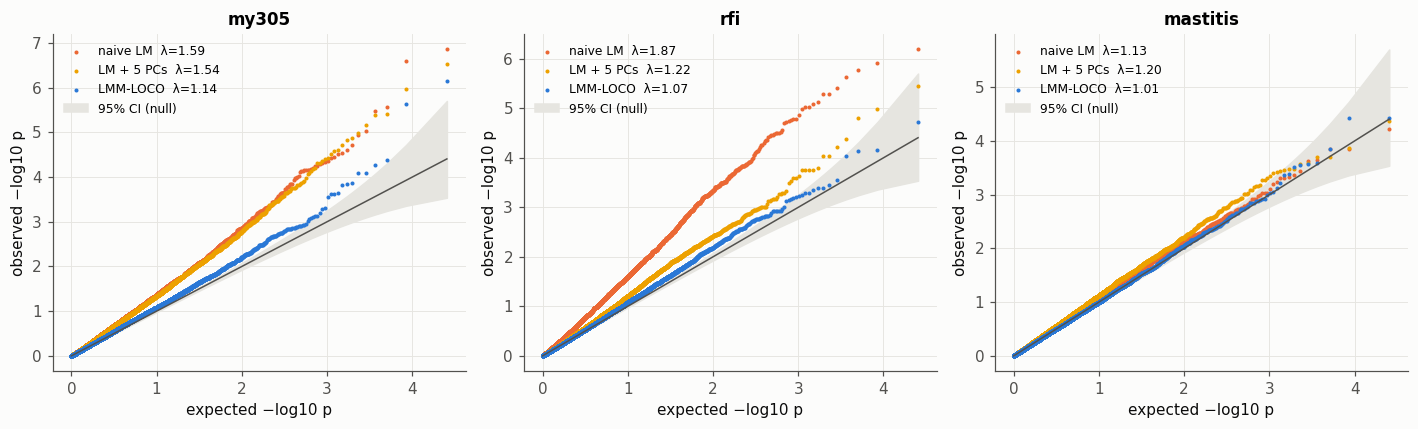

In [ ]:
def qq(ax, p, label, col):
    p = np.sort(np.asarray(p)); n = len(p); e = -np.log10((np.arange(1, n+1) - 0.5) / n)
    ax.scatter(e, -np.log10(p), s=7, color=col, label=f'{label}  λ={lam_gc(p):.2f}', linewidth=0, rasterized=True)
    return e, n

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, t in zip(ax, TRAITS):
    for mname, col in MODEL_COL.items():
        e, n = qq(a, res[(res.trait == t) & (res.model == mname)].P, mname, col)
    k = np.arange(1, n+1)   # 95% CI from order-statistic Beta distribution
    lo, hi = -np.log10(stats.beta.ppf(0.975, k, n - k + 1)), -np.log10(stats.beta.ppf(0.025, k, n - k + 1))
    a.fill_between(e, lo, hi, color=C['grid'], zorder=0, label='95% CI (null)')
    a.plot([0, e.max()], [0, e.max()], color=C['ink2'], lw=1)
    a.set(title=t, xlabel='expected −log10 p', ylabel='observed −log10 p'); a.legend(fontsize=8, loc='upper left')
fig.tight_layout(); save(fig, '08_qq_models')

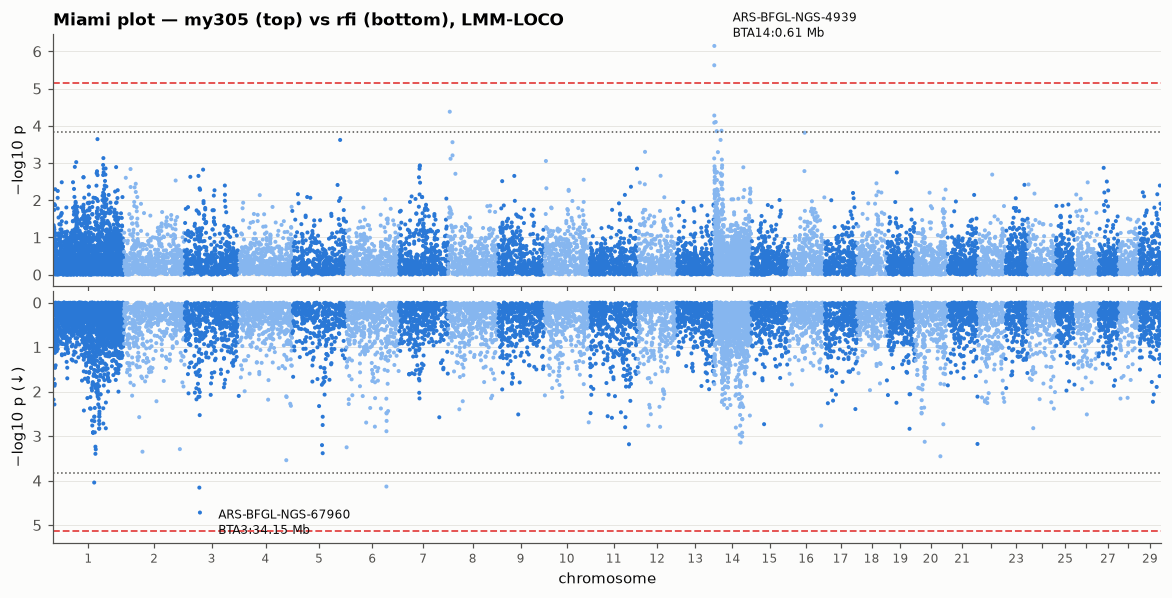

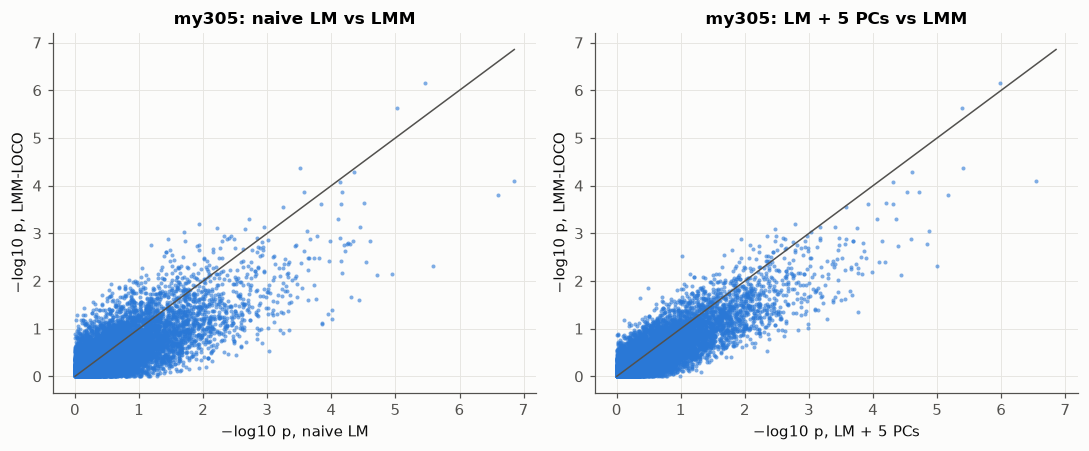

In [ ]:
# Miami plot: my305 (up) vs rfi (down), LMM-LOCO — shared vs trait-specific loci
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw=dict(hspace=0.02))
manhattan(ax[0], lmm[lmm.trait == 'my305'], 'Miami plot — my305 (top) vs rfi (bottom), LMM-LOCO')
manhattan(ax[1], lmm[lmm.trait == 'rfi'], '', flip=True)
ax[1].set_xlabel('chromosome'); save(fig, '09_miami_my305_rfi')

# model comparison: how relatedness control shrinks / reshuffles signals
w = res[res.trait == 'my305'].pivot_table(index='SNP', columns='model', values='P')
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, m in zip(ax, ['naive LM', 'LM + 5 PCs']):
    a.scatter(-np.log10(w[m]), -np.log10(w['LMM-LOCO']), s=7, color=C['blue'], alpha=0.6, linewidth=0, rasterized=True)
    mx = -np.log10(w.min().min()); a.plot([0, mx], [0, mx], color=C['ink2'], lw=1)
    a.set(xlabel=f'−log10 p, {m}', ylabel='−log10 p, LMM-LOCO', title=f'my305: {m} vs LMM')
fig.tight_layout(); save(fig, '10_model_comparison')

## 9. LD clumping → independent lead SNPs

`plink2 --clump` groups SNPs within 1 Mb and r² > 0.1 of an index SNP. Index threshold here is the
lenient p < 1e-4 for teaching; report only those passing the M_eff threshold as genome-wide significant.

In [ ]:
leads = []
for t in TRAITS:
    d = lmm[lmm.trait == t]
    d[['SNP','P']].rename(columns={'SNP': 'ID'}).to_csv(f'out/clump_{t}.txt', sep='\t', index=False)
    run(f'{PL} --bfile {QC} --clump out/clump_{t}.txt --clump-p1 1e-4 --clump-p2 1e-2 --clump-r2 0.1 '
        f'--clump-kb 1000 --clump-id-field ID --clump-p-field P --out out/clump_{t}')
    if os.path.exists(f'out/clump_{t}.clumps'):
        c = read_tab(f'out/clump_{t}.clumps')
        c = c.merge(d, left_on='ID', right_on='SNP', suffixes=('', '_g'))
        for _, r in c.iterrows():
            leads.append(dict(trait=t, SNP=r.SNP, CHR=r.CHR, BP=r.BP, A1=r.A1, FREQ=r.FREQ, BETA=r.BETA, SE=r.SE,
                              P=r.P, n_clumped=r.TOTAL, genome_wide=r.P < THR['sig'], suggestive=r.P < THR['sugg']))
leads = pd.DataFrame(leads).sort_values(['trait', 'P'])
leads.to_csv('out/lead_snps.tsv', sep='\t', index=False)
display(leads.style.format({'FREQ': '{:.3f}', 'BETA': '{:.3g}', 'SE': '{:.3g}', 'P': '{:.2e}', 'BP': '{:,.0f}'}))

,trait,SNP,CHR,BP,A1,FREQ,BETA,SE,P,n_clumped,genome_wide,suggestive
7,mastitis,ARS-BFGL-NGS-97688,11,"30,532,607",A,0.036,0.207,0.0502,3.76e-05,1,False,True
0,my305,ARS-BFGL-NGS-4939,14,"609,870",G,0.322,-436,87.9,7.16e-07,14,True,True
1,my305,BTB-01276504,8,"4,218,936",A,0.180,419,102,4.19e-05,2,False,True
2,my305,Hapmap22783-BTC-068255,14,"3,708,391",A,0.299,345,87.5,7.92e-05,26,False,True
3,rfi,ARS-BFGL-NGS-67960,3,"34,149,958",G,0.358,1.17,0.274,1.91e-05,3,False,True
4,rfi,Hapmap40909-BTA-121580,3,"32,832,755",G,0.496,-1.05,0.264,6.95e-05,9,False,True
5,rfi,Hapmap49816-BTA-98191,6,"90,169,101",G,0.466,-1.1,0.278,7.34e-05,8,False,True
6,rfi,BTA-24325-no-rs,1,"91,806,937",G,0.149,1.52,0.389,9.04e-05,5,False,True


## 10. Regional association plot (LocusZoom-style)

Points coloured by r² with the lead SNP (computed in this cohort). No gene track is drawn because
the gene annotation (ARS-UCD build/version) has not been confirmed for this array — add one from
Ensembl/NCBI once the build is verified.

my305 lead = ARS-BFGL-NGS-4939, the classic DGAT1 (K232A) tag SNP on BTA14 — positive control recovered.


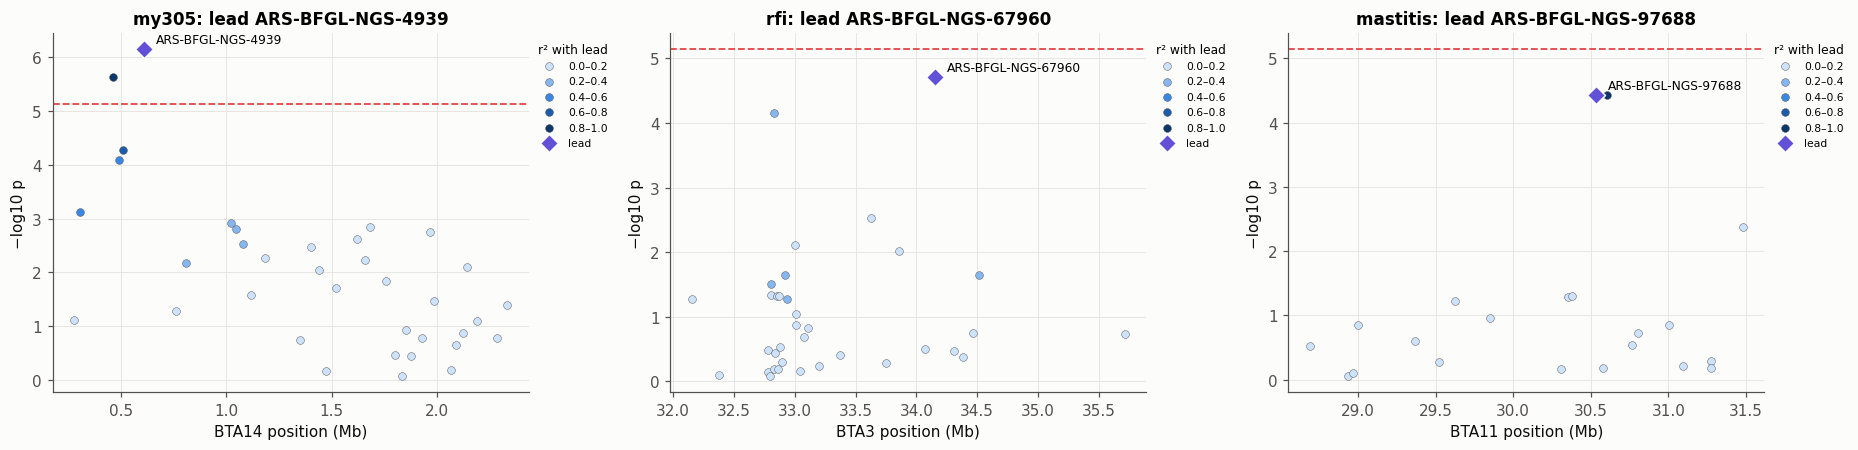

In [ ]:
R2_BINS = [0, 0.2, 0.4, 0.6, 0.8, 1.01]
R2_COLS = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']

def regional(ax, d, lead_snp, win=2e6, title=''):
    L = d.set_index('SNP').loc[lead_snp]
    reg = d[(d.CHR == L.CHR) & (d.BP.between(L.BP - win, L.BP + win))].copy()
    X = Xall[reg.SNP]; r2 = X.corrwith(Xall[lead_snp]) ** 2
    reg['r2'] = reg.SNP.map(r2)
    reg['bin'] = pd.cut(reg.r2, R2_BINS, labels=False, right=False)
    for k in range(5):
        s = reg[reg.bin == k]
        ax.scatter(s.BP/1e6, -np.log10(s.P), s=26, color=R2_COLS[k], edgecolor=C['ink2'], linewidth=0.3,
                   label=f'{R2_BINS[k]:.1f}–{min(R2_BINS[k+1],1):.1f}')
    ax.scatter(L.BP/1e6, -np.log10(L.P), marker='D', s=70, color=C['violet'], edgecolor='white', linewidth=1, zorder=5, label='lead')
    ax.annotate(lead_snp, (L.BP/1e6, -np.log10(L.P)), xytext=(8, 4), textcoords='offset points', fontsize=8)
    ax.axhline(-np.log10(THR['sig']), color=C['red'], lw=1.2, ls='--')
    ax.set(xlabel=f'BTA{int(L.CHR)} position (Mb)', ylabel='−log10 p', title=title)
    ax.legend(title='r² with lead', fontsize=7, title_fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    return reg

top = {t: lmm.loc[lmm[lmm.trait == t].P.idxmin(), 'SNP'] for t in TRAITS}   # same rule as Manhattan annotation
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a, t in zip(ax, TRAITS):
    regional(a, lmm[lmm.trait == t], top[t], title=f'{t}: lead {top[t]}')
fig.tight_layout(); save(fig, '11_regional')
if top['my305'] == 'ARS-BFGL-NGS-4939':
    print('my305 lead = ARS-BFGL-NGS-4939, the classic DGAT1 (K232A) tag SNP on BTA14 — positive control recovered.')

## 11. Conditional analysis

Add the lead SNP's dosage as a covariate and re-run the LMM. Residual signal in the region points to a
**second independent variant** (allelic heterogeneity) rather than LD with the lead.

Best other SNP within ±2 Mb — marginal: ARS-BFGL-NGS-57820 p=2.4e-06;  conditional: ARS-BFGL-NGS-32047 p=3.7e-02
-> no independent second signal


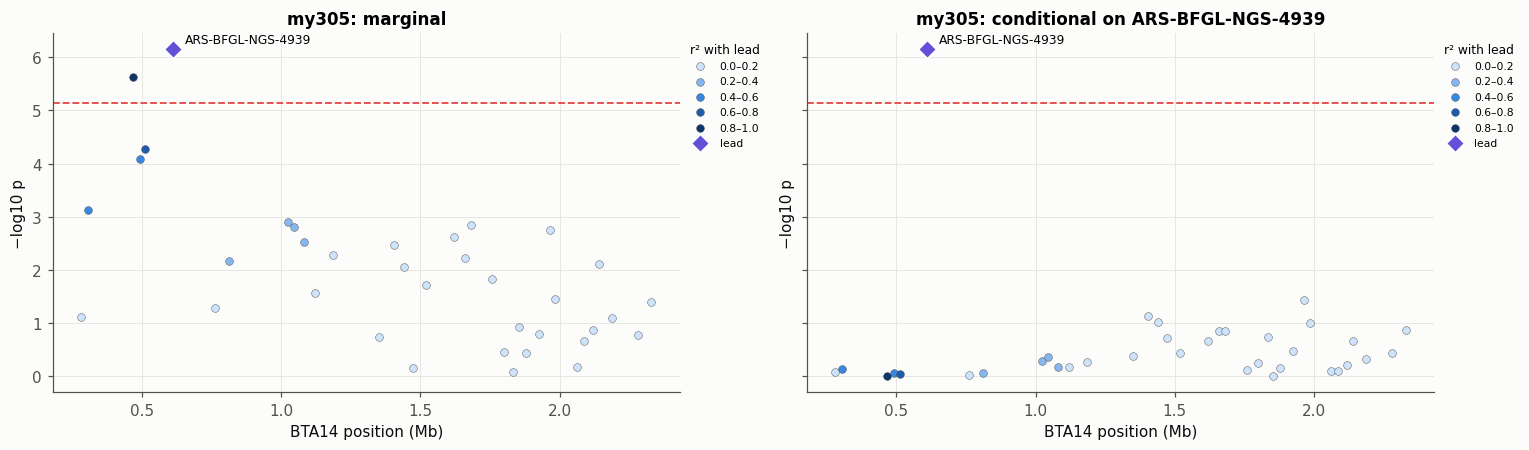

In [ ]:
t, lead = 'my305', top['my305']
qc = pd.read_csv('out/pcs5.qcovar', sep=' ', header=None)
qc[7] = qc[1].map(Xall[lead]).values
qc.to_csv('out/pcs5_cond.qcovar', sep=' ', header=False, index=False)
run(f'{GC} --mlma-loco --bfile {QC} --pheno out/{t}.phen --qcovar out/pcs5_cond.qcovar --out out/lmm_{t}_cond')
cond = std_gcta(f'out/lmm_{t}_cond.loco.mlma', t, 'LMM-LOCO | lead')
cond = pd.concat([cond[cond.SNP != lead], lmm[(lmm.trait == t) & (lmm.SNP == lead)]])   # lead itself is collinear -> keep its marginal p for the plot

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
regional(ax[0], lmm[lmm.trait == t], lead, title=f'{t}: marginal')
r = regional(ax[1], cond, lead, title=f'{t}: conditional on {lead}')
fig.tight_layout(); save(fig, '12_conditional')
L = lmm[(lmm.trait == t) & (lmm.SNP == lead)].iloc[0]
inreg = lambda d: d[(d.CHR == L.CHR) & d.BP.between(L.BP - 2e6, L.BP + 2e6) & (d.SNP != lead)]
before, after = inreg(lmm[lmm.trait == t]).sort_values('P').iloc[0], inreg(cond).sort_values('P').iloc[0]
print(f'Best other SNP within ±2 Mb — marginal: {before.SNP} p={before.P:.1e};  conditional: {after.SNP} p={after.P:.1e}')
print('-> no independent second signal' if after.P > THR['sugg'] else '-> possible second independent signal')

## 12. Effect-size plots: genotype–phenotype, cross-trait effects, effect vs MAF

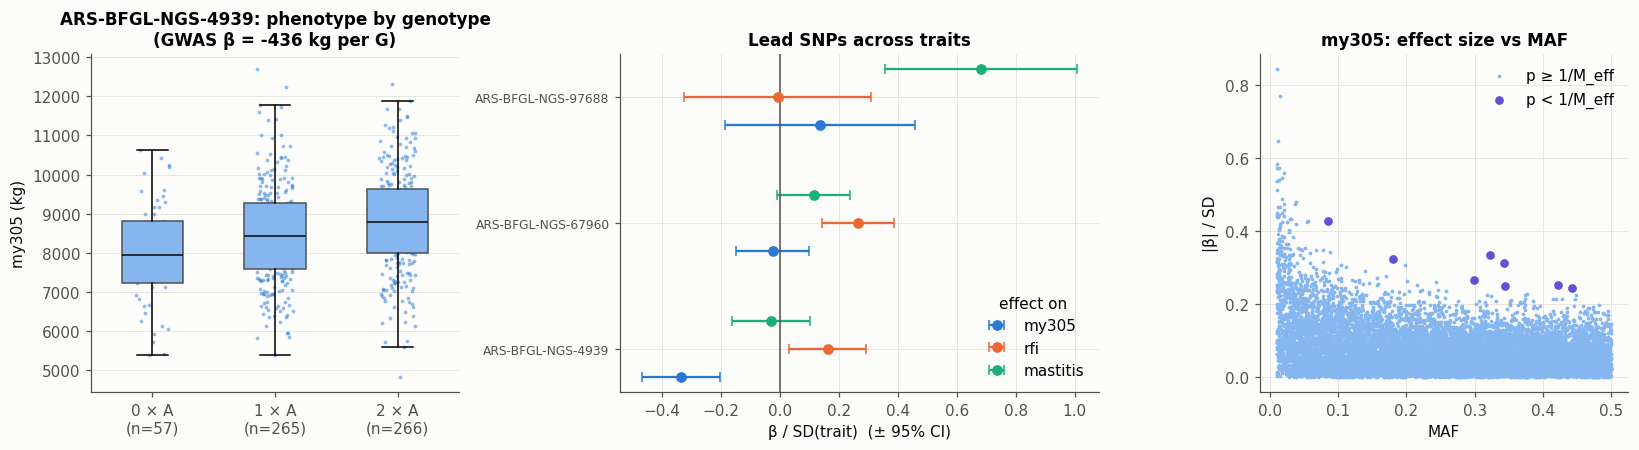

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw=dict(width_ratios=[1, 1.3, 1]))
# (a) phenotype by genotype at the my305 lead SNP
g = Xall[lead].round().reindex(pheno.IID.values).values
df = pheno.assign(g=g).dropna(subset=['g', 'my305'])
A1 = COUNTED[lead]   # allele counted in the dosage (may differ from the GWAS effect allele)
grp = [df[df.g == k].my305 for k in (0, 1, 2)]
bp_ = ax[0].boxplot(grp, positions=[0, 1, 2], widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color=C['ink']), boxprops=dict(facecolor=C['light'], edgecolor=C['ink2']))
rng = np.random.default_rng(1)
for k in (0, 1, 2):
    ax[0].scatter(k + rng.uniform(-0.15, 0.15, len(grp[k])), grp[k], s=6, color=C['blue'], alpha=0.5, linewidth=0)
ax[0].set_xticks([0, 1, 2]); ax[0].set_xticklabels([f'{k} × {A1}\n(n={len(grp[k])})' for k in (0, 1, 2)])
eff = lmm[(lmm.trait == 'my305') & (lmm.SNP == lead)].iloc[0]
ax[0].set(ylabel='my305 (kg)', title=f'{lead}: phenotype by genotype\n(GWAS β = {eff.BETA:+.0f} kg per {eff.A1})'); ax[0].grid(axis='x')

# (b) standardised effects of each trait's lead SNP on all three traits (pleiotropy check)
sd = pheno[TRAITS].std()
ls_ = list(dict.fromkeys(top.values()))
for j, (t2, col) in enumerate(zip(TRAITS, [C['blue'], C['orange'], C['aqua']])):
    e = lmm[(lmm.trait == t2) & lmm.SNP.isin(ls_)].set_index('SNP').loc[ls_]
    y = np.arange(len(ls_)) + (j - 1) * 0.22
    ax[1].errorbar(e.BETA / sd[t2], y, xerr=1.96 * e.SE / sd[t2], fmt='o', ms=6, color=col, capsize=3, lw=1.5, label=t2)
ax[1].axvline(0, color=C['ink2'], lw=1); ax[1].set_yticks(range(len(ls_))); ax[1].set_yticklabels(ls_, fontsize=8)
ax[1].set(xlabel='β / SD(trait)  (± 95% CI)', title='Lead SNPs across traits'); ax[1].legend(title='effect on')

# (c) effect size vs MAF (my305) — rare variants have large but noisy β
d = lmm[lmm.trait == 'my305'].copy(); d['MAF'] = np.minimum(d.FREQ, 1 - d.FREQ)
sig = d.P < THR['sugg']
ax[2].scatter(d.MAF[~sig], d.BETA[~sig].abs() / sd['my305'], s=6, color=C['light'], linewidth=0, rasterized=True, label='p ≥ 1/M_eff')
ax[2].scatter(d.MAF[sig], d.BETA[sig].abs() / sd['my305'], s=22, color=C['violet'], label='p < 1/M_eff')
ax[2].set(xlabel='MAF', ylabel='|β| / SD', title='my305: effect size vs MAF'); ax[2].legend()
fig.tight_layout(); save(fig, '13_effects')

## 13. Summary of outputs

In [ ]:
summary = lam.round(2).copy()
summary['h2_SNP'] = h2.set_index('trait').apply(lambda r: f'{r.h2:.2f} ± {r.se:.2f} ({r.scale})', axis=1)
summary['min p (LMM)'] = lmm.groupby('trait').P.min().map('{:.1e}'.format)
summary['lead SNP (LMM)'] = pd.Series(top)
summary['n ≥ 0.05/M_eff'] = lmm.groupby('trait').apply(lambda d: (d.P < THR['sig']).sum())
display(summary)
summary.to_csv('out/summary_by_trait.tsv', sep='\t')
print('figures:', sorted(os.listdir('figures')))
print('tables : out/gwas_all_results.tsv.gz, out/lead_snps.tsv, out/summary_by_trait.tsv')

/tmp/ipykernel_586/3870808464.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary['n ≥ 0.05/M_eff'] = lmm.groupby('trait').apply(lambda d: (d.P < THR['sig']).sum())


model,naive LM,LM + 5 PCs,LMM-LOCO,h2_SNP,min p (LMM),lead SNP (LMM),n ≥ 0.05/M_eff
trait,,,,,,,
mastitis,1.13,1.20,1.01,0.53 ± 0.22 (liability),3.8e-05,ARS-BFGL-NGS-97688,0
my305,1.59,1.54,1.14,0.42 ± 0.08 (observed),7.2e-07,ARS-BFGL-NGS-4939,2
rfi,1.87,1.22,1.07,0.41 ± 0.08 (observed),1.9e-05,ARS-BFGL-NGS-67960,0


figures: ['01_phenotypes.png', '02_qc_panels.png', '03_ld_decay.png', '04_pca.png', '05_grm.png', '06_h2.png', '07_manhattan_lmm.png', '08_qq_models.png', '09_miami_my305_rfi.png', '10_model_comparison.png', '11_regional.png', '12_conditional.png', '13_effects.png']
tables : out/gwas_all_results.tsv.gz, out/lead_snps.tsv, out/summary_by_trait.tsv


## 14. Caveats and next steps

* **Power.** n = 588 detects only large-effect QTL (DGAT1-class). Null results for RFI/mastitis are expected, not evidence of absence.
* **Missing fixed effects.** Breed, parity, calving year-season and herd management are not in this subset. In production
  analyses fit them as fixed effects (see `03_genomic_qc_gwas.md`); PCs are not a substitute for breed when Holstein and Jersey are pooled.
* **Repeated measures.** Here traits are one value per cow. With test-day or multi-lactation data use a repeatability
  model (permanent environment effect) or de-regressed EBVs as the response.
* **Thinned chromosomes.** Bonferroni/M_eff and λ are computed on an uneven SNP density; genome-wide runs should use
  the full `setB_dense` panel (37k SNPs) or imputed HD (777k) genotypes.
* **Binary trait.** Liability h² depends on the assumed prevalence; consider SAIGE/GMMAT for exact logistic GLMM GWAS.
* **Build & annotation.** Verify ARS-UCD1.2 vs 2.0 coordinates from the manifest before gene/pathway lookup.
* **Next:** full-panel run, permutation thresholds, conditional-joint (GCTA-COJO) fine-mapping, multi-trait GWAS,
  and replication in partner AgData herds.